In [ ]:
#google drive a bağlanma
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import numpy as np
import pandas as pd
import librosa
from tensorflow.keras.models import Model
from tensorflow.keras.layers import *
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings("ignore")

CSV_PATH = "/content/drive/MyDrive/HateSpeechProject/Rapor_v1/veriseti/toplamkarisikveriseti/deney/labels.csv"
AUDIO_DIR = "/content/drive/MyDrive/HateSpeechProject/Rapor_v1/veriseti/toplamkarisikveriseti/deney/sesler"

# ============================================================
# 1. AUGMENTATION FONKSİYONLARI
# ============================================================

def shift_pitch(y, sr, n_steps):
    try:
        return librosa.effects.pitch_shift(y, sr=sr, n_steps=n_steps)
    except:
        return y

def add_noise(y, noise_factor=0.005):
    noise = np.random.randn(len(y))
    return y + noise_factor * noise


def augment_audio_11x(y, sr):
    """
    11x Augmentation - SADECE Pitch Shift + Noise
    Sadece TRAIN için kullanılır

    288 train dosya × 11 = 3,168 train örneği
    72 test dosya × 1 = 72 test örneği (orijinal)
    """
    augmented = [y]  # 1. Orijinal

    # Noise variations (5 versiyon)
    for factor in [0.002, 0.004, 0.006, 0.008, 0.010]:
        augmented.append(add_noise(y, noise_factor=factor))

    # Pitch shift (5 versiyon)
    for n in [-3, -2, -1, 1, 2]:
        augmented.append(shift_pitch(y, sr, n_steps=n))

    return augmented  # Toplam 11 versiyon (1 + 5 noise + 5 pitch)

# ============================================================
# 2. ÖZELLİK ÇIKARIMI
# ============================================================

def extract_features_single(y, sr, max_len=250):
    """Tek bir audio için özellik çıkarımı"""
    try:
        # MEL
        mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
        mel = librosa.power_to_db(mel, ref=np.max)
        if mel.shape[1] > max_len:
            mel = mel[:, :max_len]
        else:
            mel = np.pad(mel, ((0,0),(0,max_len - mel.shape[1])), mode="constant")
        mel = mel.T

        # PROSODIC
        rms = librosa.feature.rms(y=y).ravel()
        zcr = librosa.feature.zero_crossing_rate(y).ravel()
        tempo,_ = librosa.beat.beat_track(y=y, sr=sr)
        tempo = float(tempo)
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
        mfcc_mean = mfcc.mean(axis=1).ravel()

        prosodic = np.concatenate([
            [rms.mean(), rms.std()],
            [zcr.mean(), zcr.std()],
            [tempo],
            mfcc_mean
        ]).astype(np.float32)

        return mel, prosodic

    except Exception as e:
        return None, None

# ============================================================
# 3. VERİ HAZIRLAMA - AUGMENTATION OLMADAN
# ============================================================

def prepare_base_dataset(csv_path, audio_dir):
    """
    Önce tüm veriyi augmentation OLMADAN yükle
    """
    df = pd.read_csv(csv_path)
    X_mel, X_pros, y_tone, y_content, sentence_ids, file_indices = [], [], [], [], [], []

    print("📥 Temel veri yükleniyor (augmentation yok)...")
    for idx, row in df.iterrows():
        audio_path = os.path.join(audio_dir, row["name"])
        if not os.path.exists(audio_path):
            continue

        try:
            y, sr = librosa.load(audio_path, sr=22050)
            if len(y) < sr*0.5:
                continue

            mel, prosodic = extract_features_single(y, sr)

            if mel is not None:
                X_mel.append(mel)
                X_pros.append(prosodic)
                y_tone.append(row["tone"])
                y_content.append(row["content"])
                sentence_ids.append(row["sentence_id"])
                file_indices.append(idx)  # Dosya indeksi

        except Exception as e:
            continue

        if (idx + 1) % 50 == 0:
            print(f"   {idx + 1}/{len(df)} dosya işlendi...", end='\r')

    print(f"\n✅ Temel veri: {len(X_mel)} dosya")

    return (np.array(X_mel), np.array(X_pros),
            np.array(y_tone), np.array(y_content),
            np.array(sentence_ids), np.array(file_indices), df)

# ============================================================
# 4. SADECE TRAIN SETİNE AUGMENTATION UYGULA
# ============================================================

def apply_augmentation_to_train(df, train_file_indices, audio_dir):
    """
    ✅ SADECE TRAIN setine 11x augmentation uygula
    ❌ TEST seti hiç augment edilmez

    Her train dosyası: 1 orijinal + 10 augmented = 11 toplam
    """
    X_mel_aug, X_pros_aug = [], []

    print(f"\n🔄 SADECE TRAIN setine 11x augmentation uygulanıyor...")
    print(f"   {len(train_file_indices)} train dosyası")
    print(f"   Her dosya × 11 = {len(train_file_indices)*11} train örneği hedefi")
    print(f"   (Her dosyadan 10 augmented versiyon üretiliyor...)")

    for i, idx in enumerate(train_file_indices):
        row = df.iloc[idx]
        audio_path = os.path.join(audio_dir, row["name"])

        try:
            y, sr = librosa.load(audio_path, sr=22050)

            # 11 versiyon oluştur
            augmented_versions = augment_audio_11x(y, sr)

            # İlk versiyonu atla (orijinal zaten base'de var)
            # Sadece 10 augmented versiyonu ekle
            for y_aug in augmented_versions[1:]:  # 10 augmented versiyon
                mel, prosodic = extract_features_single(y_aug, sr)
                if mel is not None:
                    X_mel_aug.append(mel)
                    X_pros_aug.append(prosodic)
        except:
            continue

        if (i + 1) % 20 == 0:
            print(f"   {i+1}/{len(train_file_indices)} dosya → {len(X_mel_aug)} augmented örnek", end='\r')

    print(f"\n✅ TRAIN augmentation tamamlandı: {len(X_mel_aug)} yeni örnek")

    return np.array(X_mel_aug), np.array(X_pros_aug)

# ============================================================
# 5. MODEL (LSTM VERSİYON)
# ============================================================

def build_model_for_heavy_aug(n_tone, n_content):
    """
    LSTM tabanlı model - Uzun vadeli bağımlılıklar için
    """
    mel_input = Input(shape=(250, 128), name="mel")
    pros_input = Input(shape=(18,), name="prosodic")

    # LSTM Layers (Bidirectional)
    x = Bidirectional(LSTM(128, return_sequences=True))(mel_input)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)

    x = Bidirectional(LSTM(64, return_sequences=True))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)

    x = Bidirectional(LSTM(32, return_sequences=False))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.5)(x)

    # Prosodic branch
    p = Dense(32, activation="relu")(pros_input)
    p = BatchNormalization()(p)
    p = Dropout(0.3)(p)

    # Merge
    merged = concatenate([x, p])
    merged = Dense(256, activation="relu")(merged)
    merged = BatchNormalization()(merged)
    merged = Dropout(0.5)(merged)
    merged = Dense(128, activation="relu")(merged)
    merged = BatchNormalization()(merged)
    merged = Dropout(0.5)(merged)

    # Outputs
    tone_out = Dense(n_tone, activation="softmax", name="tone")(merged)
    content_out = Dense(n_content, activation="softmax", name="content")(merged)

    model = Model(inputs=[mel_input, pros_input], outputs=[tone_out, content_out])
    return model
# ============================================================
# 6. EĞİTİM
# ============================================================

def train_with_heavy_augmentation(csv_path, audio_dir):
    """10x augmentation ile eğitim"""

    # 1. Temel veriyi yükle (augmentation yok)
    X_mel_base, X_pros_base, y_tone, y_content, sentence_ids, file_indices, df = prepare_base_dataset(
        csv_path, audio_dir
    )

    # 2. Encode
    tone_enc = LabelEncoder()
    content_enc = LabelEncoder()
    y_tone_enc = tone_enc.fit_transform(y_tone)
    y_content_enc = content_enc.fit_transform(y_content)

    print(f"\n🏷️ Ton: {tone_enc.classes_}")
    print(f"🏷️ İçerik: {content_enc.classes_}")

    # 3. Cümle bazlı split (BASE VERİ ÜZERİNDE)
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    train_base_idx, test_base_idx = next(gss.split(
        X_mel_base, y_content_enc, groups=sentence_ids
    ))

    # Kontrol
    train_sentences = set(sentence_ids[train_base_idx])
    test_sentences = set(sentence_ids[test_base_idx])

    print(f"\n✅ Base split:")
    print(f"   Train: {len(train_base_idx)} dosya ({len(train_sentences)} cümle)")
    print(f"   Test: {len(test_base_idx)} dosya ({len(test_sentences)} cümle)")

    # 4. SADECE TRAIN SETİNE AUGMENTATION UYGULA
    train_file_indices = file_indices[train_base_idx]
    X_mel_aug, X_pros_aug = apply_augmentation_to_train(df, train_file_indices, audio_dir)

    # 5. SADECE TRAIN setini genişlet: Orijinal + Augmented
    # TEST seti ORİJİNAL KALIR!
    X_mel_train_full = np.concatenate([X_mel_base[train_base_idx], X_mel_aug])
    X_pros_train_full = np.concatenate([X_pros_base[train_base_idx], X_pros_aug])

    # Etiketleri tekrarla (augmented veriler için)
    y_tone_train_full = np.concatenate([
        y_tone_enc[train_base_idx],
        np.repeat(y_tone_enc[train_base_idx], 10)  # Her dosya için 10 augmented
    ])
    y_content_train_full = np.concatenate([
        y_content_enc[train_base_idx],
        np.repeat(y_content_enc[train_base_idx], 10)
    ])

    # 6. Test seti ORİJİNAL KALIR
    X_mel_test = X_mel_base[test_base_idx]
    X_pros_test = X_pros_base[test_base_idx]
    y_tone_test = y_tone_enc[test_base_idx]
    y_content_test = y_content_enc[test_base_idx]

    # 7. Normalize
    scaler = StandardScaler()
    X_pros_train_full = scaler.fit_transform(X_pros_train_full)
    X_pros_test = scaler.transform(X_pros_test)

    print(f"\n📊 FİNAL VERİ SETİ:")
    print(f"   ✅ TRAIN:")
    print(f"      - Orijinal: {len(train_base_idx)} dosya")
    print(f"      - Augmented: {len(X_mel_aug)} örnek (10 × {len(train_base_idx)})")
    print(f"      - TOPLAM: {len(X_mel_train_full)} train örneği")
    print(f"   ❌ TEST (Augmentation YOK!):")
    print(f"      - Sadece orijinal: {len(X_mel_test)} örnek")
    print(f"   📈 Train/Test oranı: {len(X_mel_train_full) / len(X_mel_test):.1f}x")

    # 8. Model
    model = build_model_for_heavy_aug(
        len(tone_enc.classes_),
        len(content_enc.classes_)
    )

    model.compile(
        optimizer=Adam(learning_rate=0.0005),  # LSTM için daha düşük LR
        loss={
            "tone": "sparse_categorical_crossentropy",
            "content": "sparse_categorical_crossentropy"
        },
        loss_weights={"tone": 0.1, "content": 0.9},
        metrics={"tone": "accuracy", "content": "accuracy"}
    )

    print(f"\n📊 Model:")
    model.summary()

    # 9. Callbacks
    callbacks = [
        EarlyStopping(
            patience=30,
            restore_best_weights=True,
            monitor='val_content_accuracy',
            mode='max',
            verbose=1
        ),
        ReduceLROnPlateau(
            patience=15,
            factor=0.5,
            monitor='val_content_accuracy',
            mode='max',
            verbose=1,
            min_lr=1e-7
        )
    ]

    # 10. Eğitim
    print("\n" + "="*60)
    print("🚀 EĞİTİM BAŞLIYOR")
    print("="*60)
    print("⚠️  ÖNEMLI:")
    print("   - TRAIN seti: 11x augmented (orijinal + 10 versiyon)")
    print("   - TEST seti: SADECE orijinal (augmentation YOK!)")
    print("   - Bu sayede gerçek performansı ölçüyoruz")
    print("="*60 + "\n")

    history = model.fit(
        [X_mel_train_full, X_pros_train_full],
        {"tone": y_tone_train_full, "content": y_content_train_full},
        validation_data=(
            [X_mel_test, X_pros_test],
            {"tone": y_tone_test, "content": y_content_test}
        ),
        epochs=200,
        batch_size=32,  # LSTM için küçük batch size
        callbacks=callbacks,
        verbose=1
    )

    # 11. Değerlendirme
    results = model.evaluate(
        [X_mel_test, X_pros_test],
        {"tone": y_tone_test, "content": y_content_test},
        verbose=0
    )

    print("\n" + "="*60)
    print("🎯 TEST SONUÇLARI (Orijinal Test Seti)")
    print("="*60)
    print(f"Tone Accuracy     : {results[3]*100:.2f}%")
    print(f"Content Accuracy  : {results[4]*100:.2f}%")

    # 12. Detaylı rapor
    tone_pred, content_pred = model.predict([X_mel_test, X_pros_test], verbose=0)
    content_pred_cls = np.argmax(content_pred, axis=1)
    tone_pred_cls = np.argmax(tone_pred, axis=1)
    # ============================================================
    # TONE RAPORU
    # ============================================================
    print("\n📊 TONE RAPORU:")
    print(classification_report(
        y_tone_test,
        tone_pred_cls,
        target_names=tone_enc.classes_,
        digits=3
    ))

    print("\n📊 TONE CONFUSION MATRIX:")
    cm_tone = confusion_matrix(y_tone_test, tone_pred_cls)
    print(f"         {tone_enc.classes_}")
    for i, row in enumerate(cm_tone):
        print(f"{tone_enc.classes_[i]:8s} {row}")

    # ============================================================
    # CONTENT RAPORU
    # ============================================================
    print("\n📊 CONTENT RAPORU:")
    print(classification_report(
        y_content_test,
        content_pred_cls,
        target_names=content_enc.classes_,
        digits=3
    ))

    print("\n📊 CONTENT CONFUSION MATRIX:")
    cm_content = confusion_matrix(y_content_test, content_pred_cls)
    print(f"         {content_enc.classes_}")
    for i, row in enumerate(cm_content):
        print(f"{content_enc.classes_[i]:8s} {row}")


    # 13. Kaydet
    model.save('hakaret_10x_aug.keras')

    import pickle
    with open('scaler_10x.pkl', 'wb') as f:
        pickle.dump(scaler, f)
    with open('tone_enc_10x.pkl', 'wb') as f:
        pickle.dump(tone_enc, f)
    with open('content_enc_10x.pkl', 'wb') as f:
        pickle.dump(content_enc, f)

    print("\n✅ Model kaydedildi")

    return model, scaler, tone_enc, content_enc, history

# ============================================================
# ÇALIŞTIR
# ============================================================

if __name__ == "__main__":
    model, scaler, tone_enc, content_enc, history = train_with_heavy_augmentation(
        CSV_PATH,
        AUDIO_DIR
    )

📥 Temel veri yükleniyor (augmentation yok)...

✅ Temel veri: 360 dosya

🏷️ Ton: ['aggresive' 'happy' 'neutral']
🏷️ İçerik: ['hateful' 'neutral' 'positive']

✅ Base split:
   Train: 288 dosya (95 cümle)
   Test: 72 dosya (24 cümle)

🔄 SADECE TRAIN setine 11x augmentation uygulanıyor...
   288 train dosyası
   Her dosya × 11 = 3168 train örneği hedefi
   (Her dosyadan 10 augmented versiyon üretiliyor...)

✅ TRAIN augmentation tamamlandı: 2880 yeni örnek

📊 FİNAL VERİ SETİ:
   ✅ TRAIN:
      - Orijinal: 288 dosya
      - Augmented: 2880 örnek (10 × 288)
      - TOPLAM: 3168 train örneği
   ❌ TEST (Augmentation YOK!):
      - Sadece orijinal: 72 örnek
   📈 Train/Test oranı: 44.0x

📊 Model:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ mel (InputLayer)    │ (None, 250, 128)  │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 250, 256)  │    263,168 │ mel[0][0]         │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 250, 256)  │      1,024 │ bidirectional[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 250, 256)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 250, 128)  │    164,352 │ dropout[0][0]     │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 250, 128)  │        512 │ bidirectional_1[… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 250, 128)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ prosodic            │ (None, 18)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_2     │ (None, 64)        │     41,216 │ dropout_1[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        608 │ prosodic[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ bidirectional_2[… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32)        │        128 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 96)        │          0 │ dropout_2[0][0],  │
│ (Concatenate)       │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │     24,832 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     32,896 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_2[0][0]   

 Total params: 531,302 (2.03 MB)

 Trainable params: 529,574 (2.02 MB)

 Non-trainable params: 1,728 (6.75 KB)


🚀 EĞİTİM BAŞLIYOR
⚠️  ÖNEMLI:
   - TRAIN seti: 11x augmented (orijinal + 10 versiyon)
   - TEST seti: SADECE orijinal (augmentation YOK!)
   - Bu sayede gerçek performansı ölçüyoruz

Epoch 1/200
99/99 ━━━━━━━━━━━━━━━━━━━━ 20s 79ms/step - content_accuracy: 0.3708 - content_loss: 1.8143 - loss: 1.8288 - tone_accuracy: 0.3396 - tone_loss: 1.9593 - val_content_accuracy: 0.3889 - val_content_loss: 1.0826 - val_loss: 1.0935 - val_tone_accuracy: 0.4028 - val_tone_loss: 1.1358 - learning_rate: 5.0000e-04
Epoch 2/200
99/99 ━━━━━━━━━━━━━━━━━━━━ 7s 66ms/step - content_accuracy: 0.3874 - content_loss: 1.5750 - loss: 1.5832 - tone_accuracy: 0.3699 - tone_loss: 1.6569 - val_content_accuracy: 0.4444 - val_content_loss: 1.0643 - val_loss: 1.0869 - val_tone_accuracy: 0.4306 - val_tone_loss: 1.1020 - learning_rate: 5.0000e-04
Epoch 3/200
99/99 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step - content_accuracy: 0.3945 - content_loss: 1.4321 - loss: 1.4408 - tone_accuracy: 0.3886 - tone_loss: 1.5188 - val_content_accu

📊 GÖRSELLEŞTİRME BAŞLIYOR (Eğitim yok!)

1️⃣ Model ve encoder'lar yükleniyor...
✅ Model yüklendi

2️⃣ Veri yükleniyor...
📥 Test verisi yükleniyor...
✅ 360 dosya yüklendi

3️⃣ Test seti ayrılıyor...
✅ Test seti hazır: 72 örnek

4️⃣ Tahminler yapılıyor...
✅ Tahminler tamamlandı

5️⃣ Grafikler çiziliyor (600 DPI)...



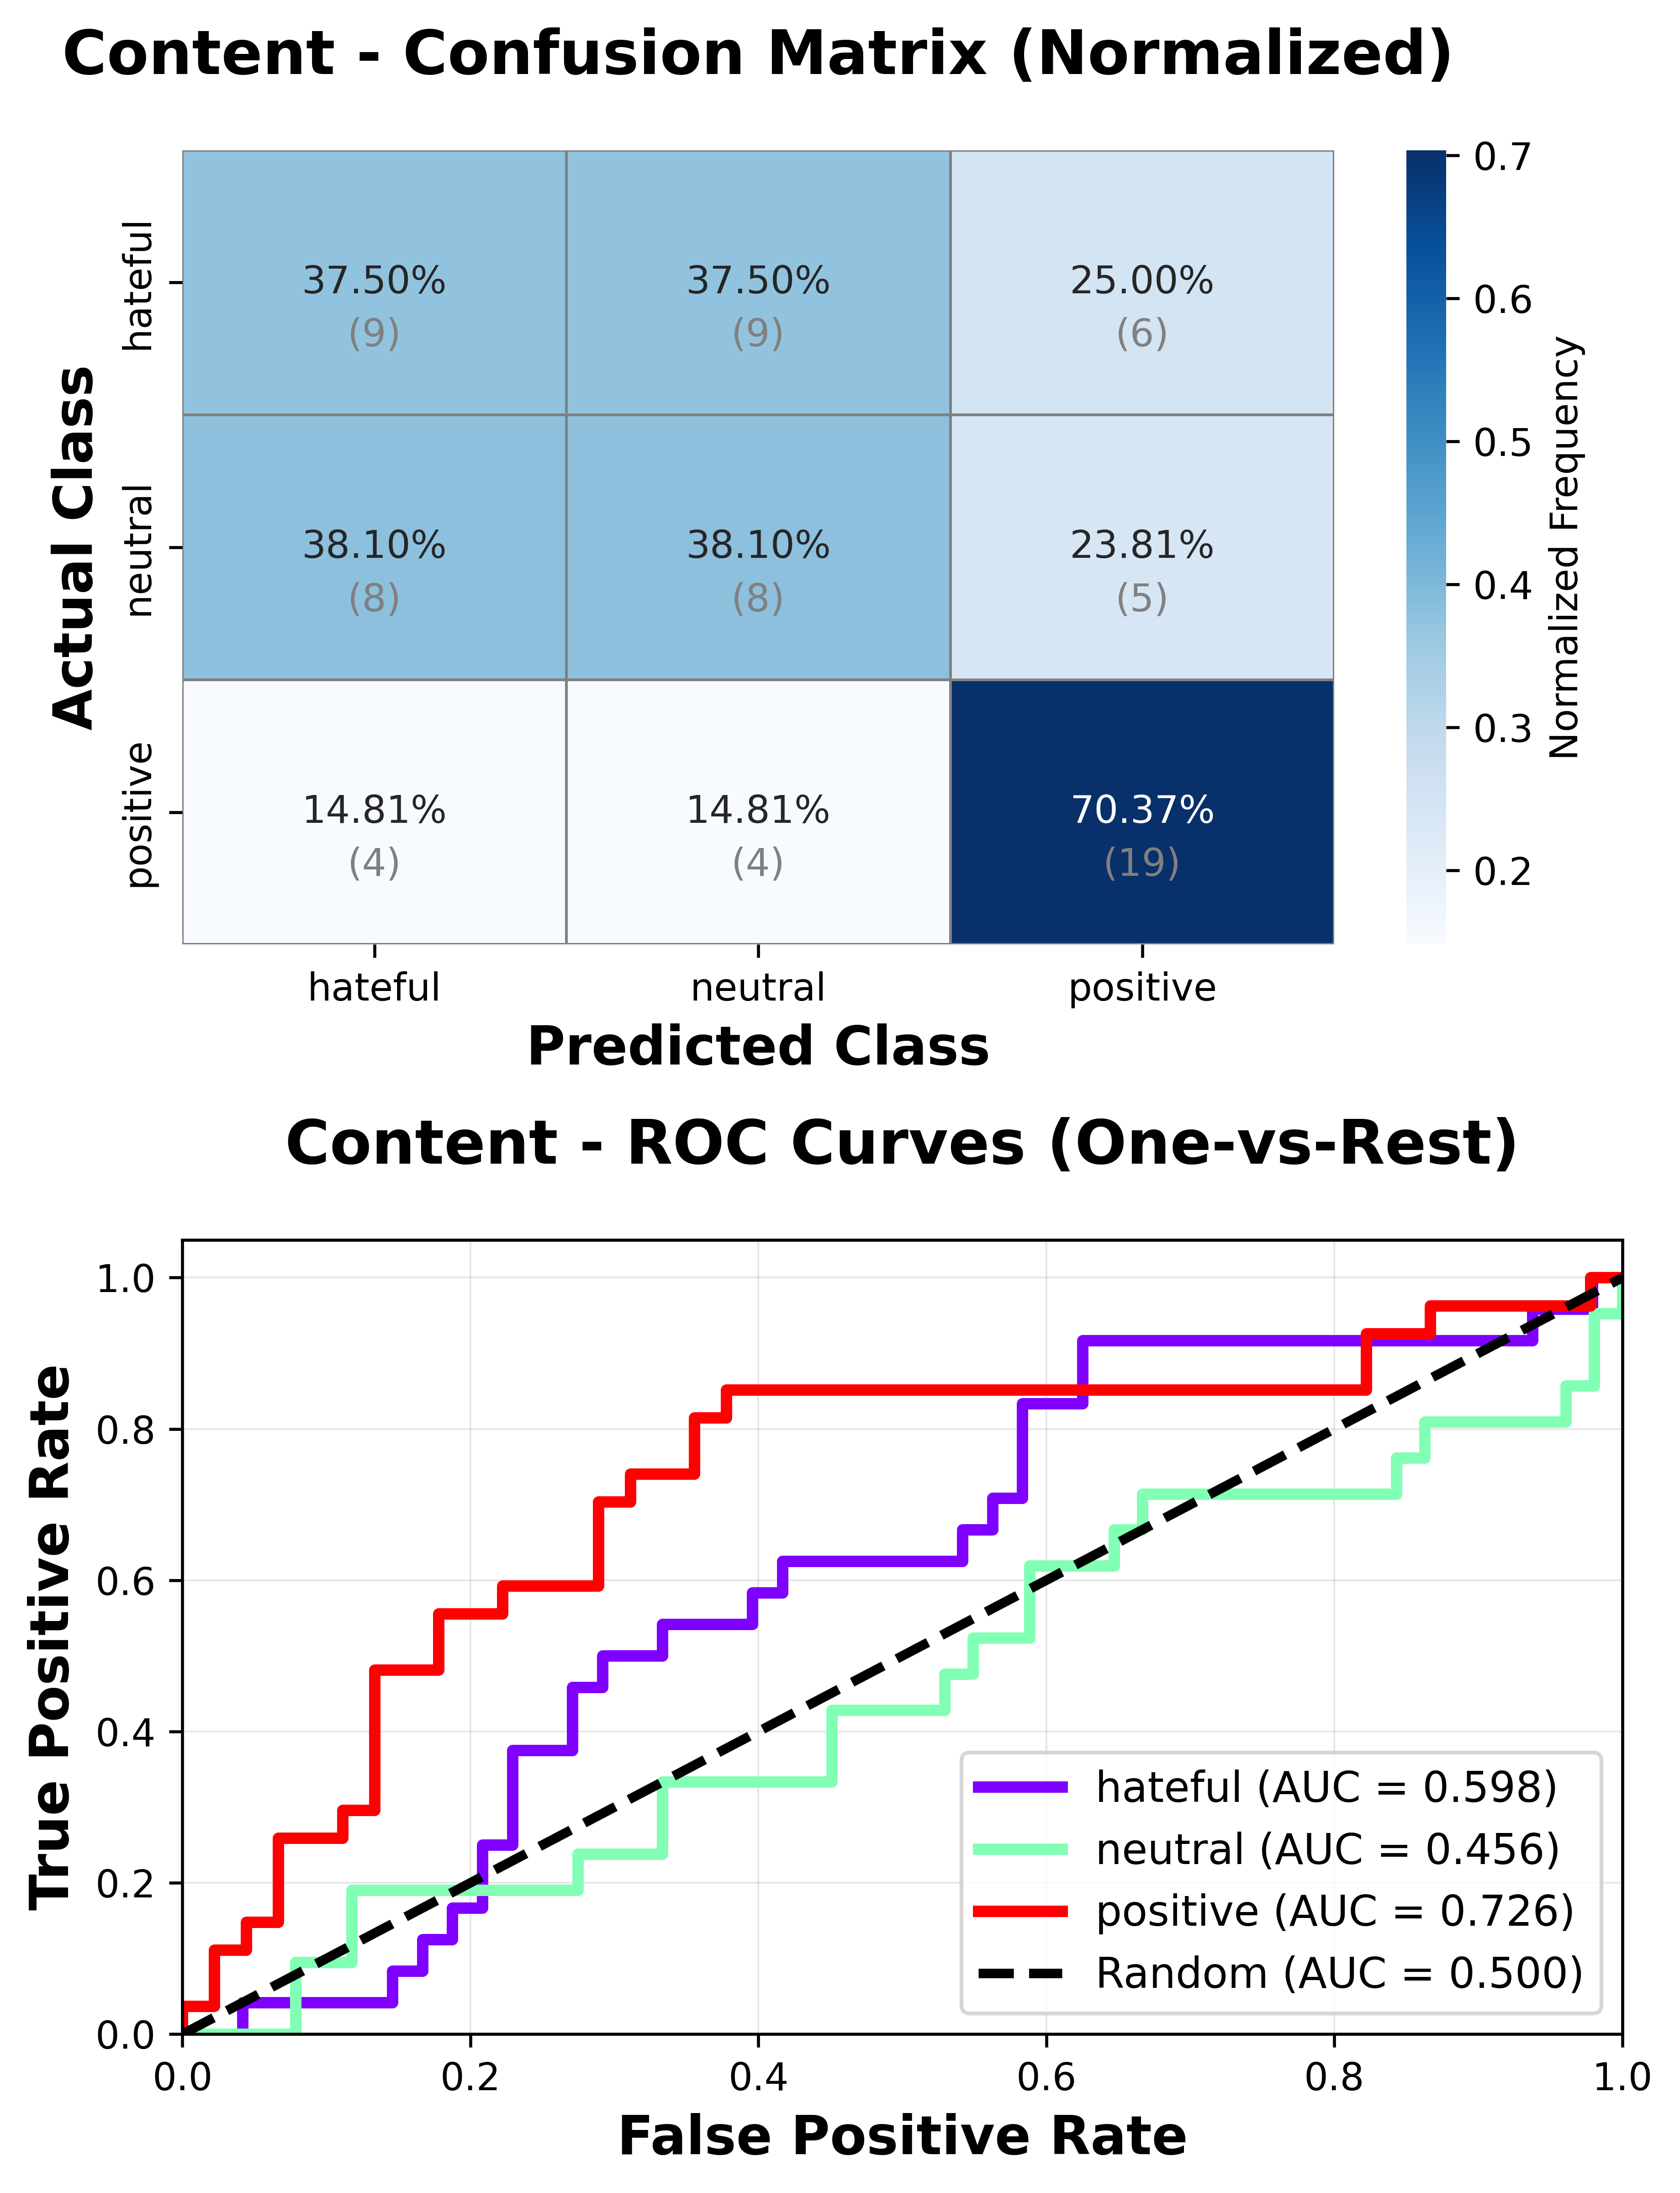

✅ Content grafikleri kaydedildi (600 DPI): content_confusion_matrix_and_roc.png


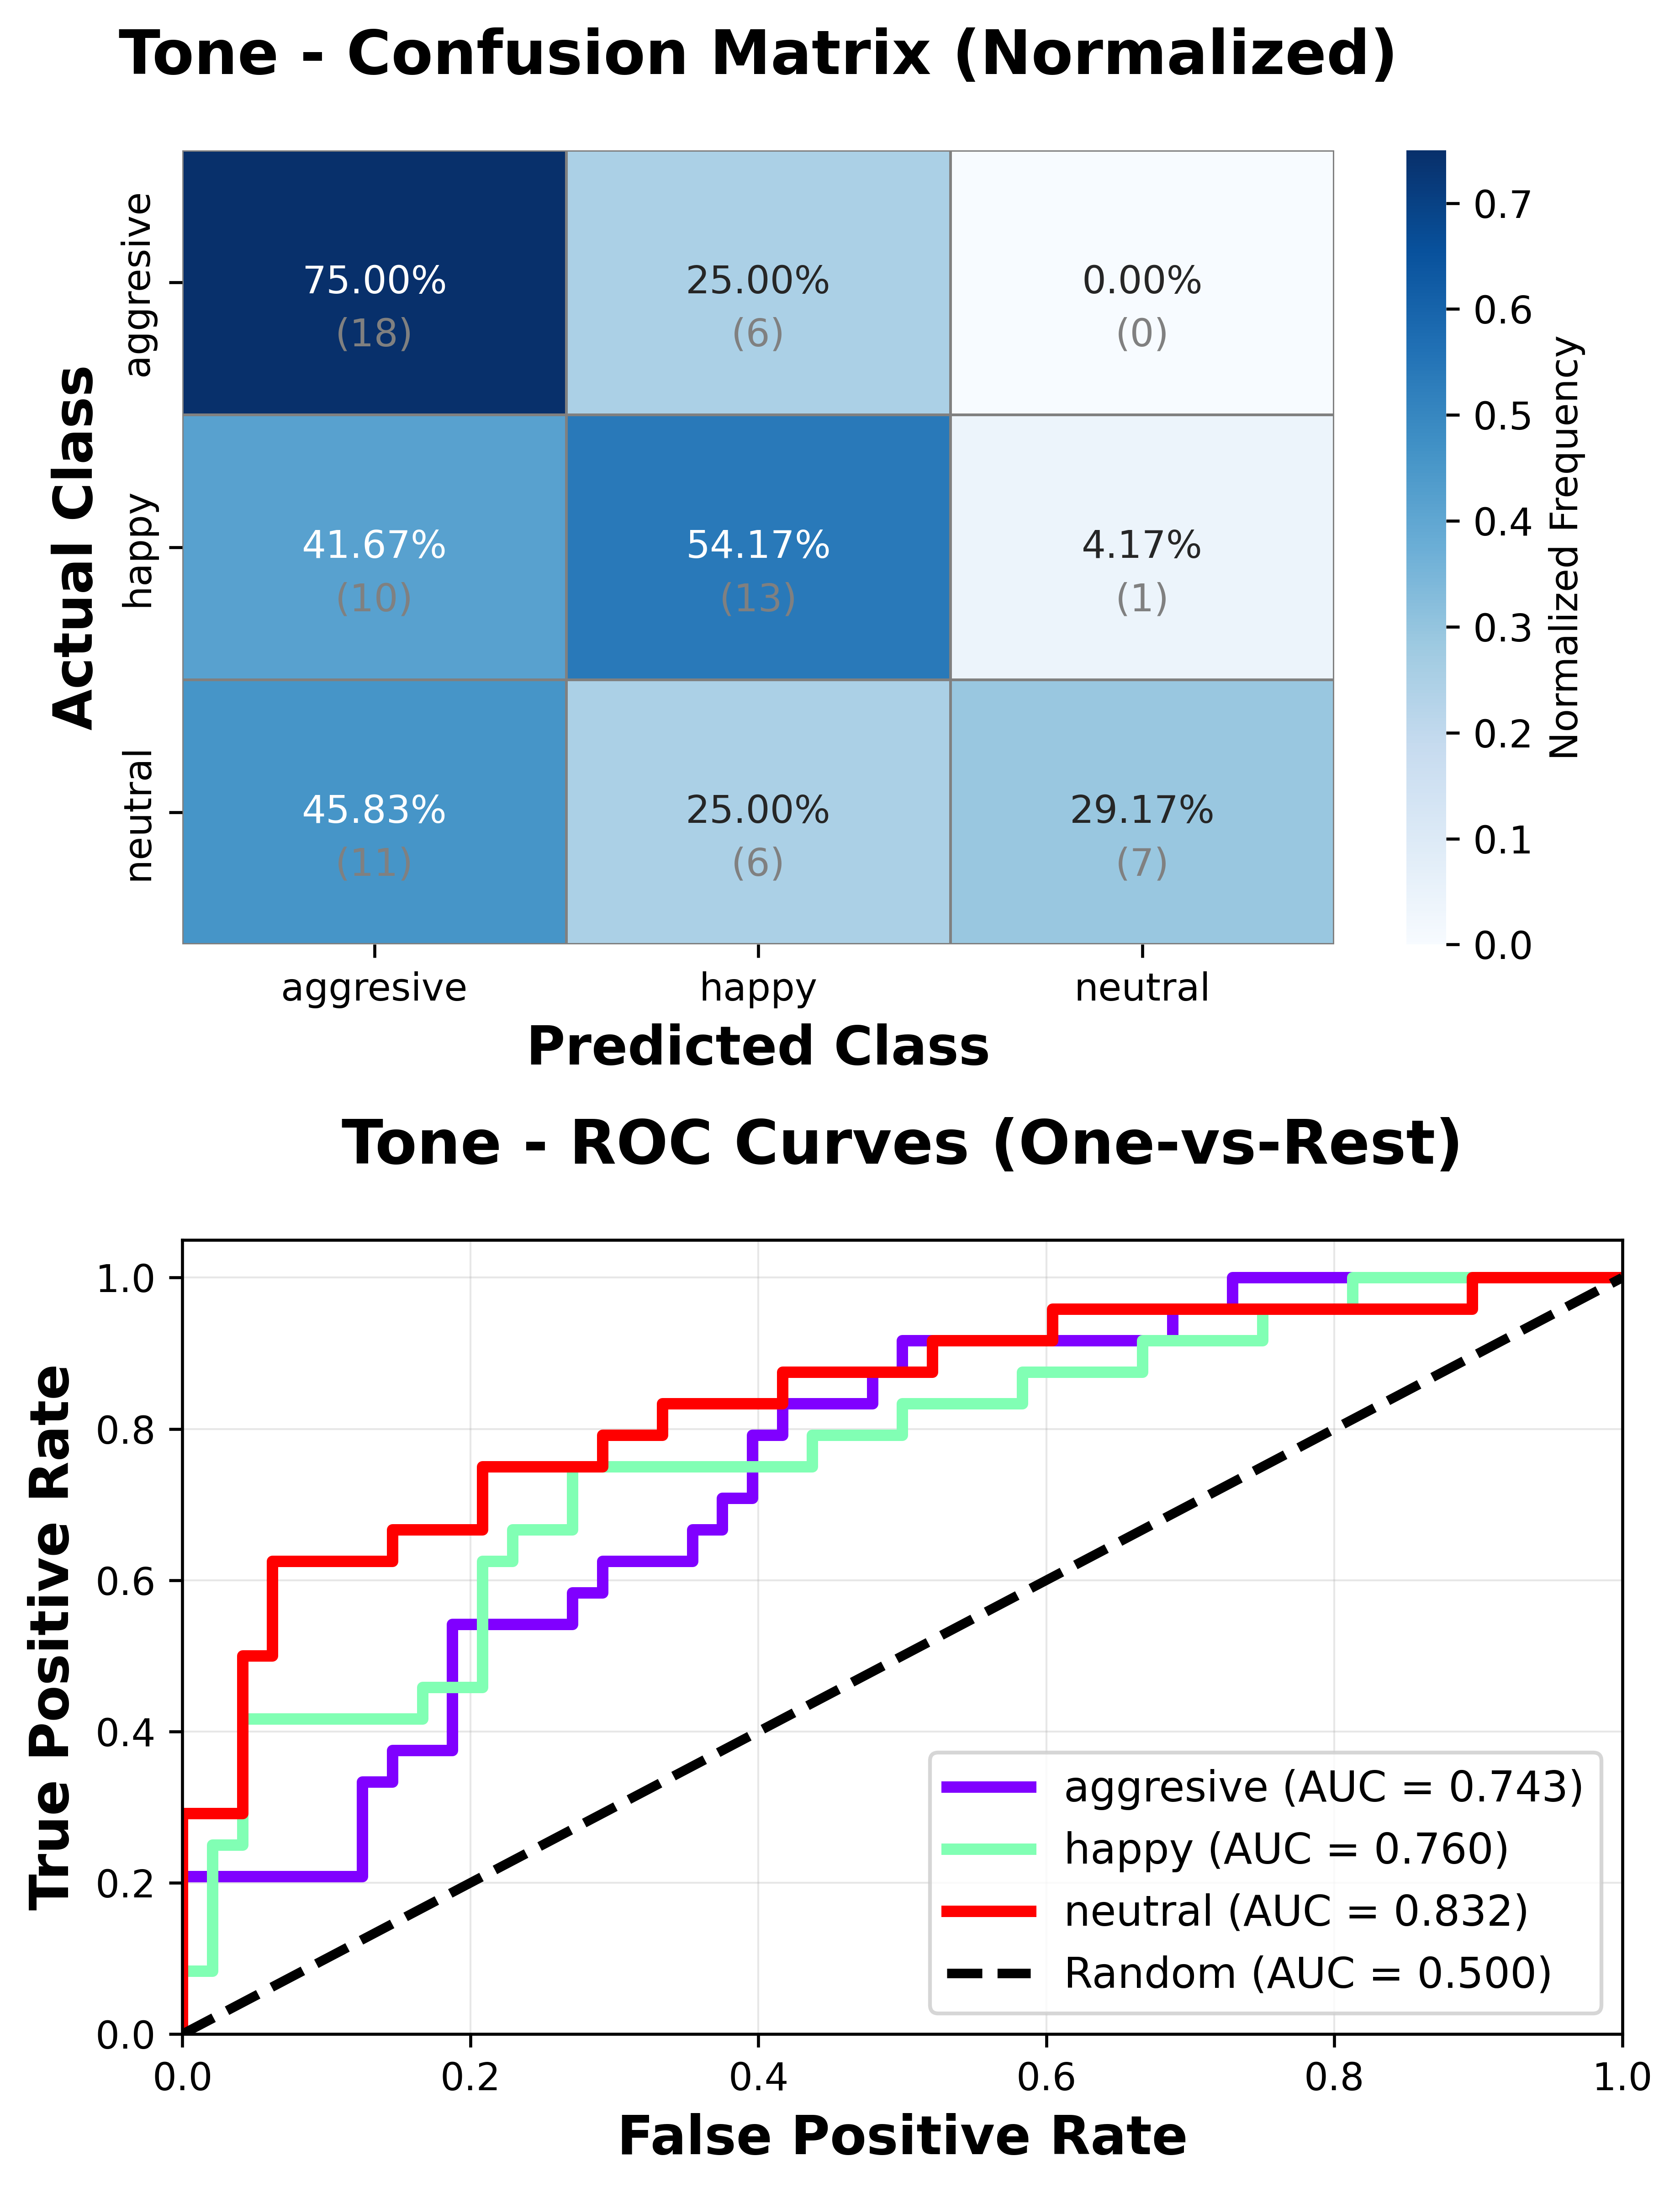

✅ Tone grafikleri kaydedildi (600 DPI): tone_confusion_matrix_and_roc.png

✅ TÜM GÖRSELLEŞTİRMELER TAMAMLANDI

📁 Kaydedilen dosyalar (600 DPI):
   - content_confusion_matrix_and_roc.png
   - tone_confusion_matrix_and_roc.png

📐 Çözünürlük: ~3740x4862 piksel (6.23 x 8.10 inch @ 600 DPI)


In [ ]:
# ============================================================
# SADECE GÖRSELLEŞTİRME - AYRI HÜCRE
# Eğitim yapmadan sadece kaydedilmiş modeli kullanır
# ============================================================

import numpy as np
import pandas as pd
import librosa
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import load_model
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
import warnings
warnings.filterwarnings("ignore")

# Ayarlar
CSV_PATH = "/content/drive/MyDrive/HateSpeechProject/Rapor_v1/veriseti/toplamkarisikveriseti/deney/labels.csv"
AUDIO_DIR = "/content/drive/MyDrive/HateSpeechProject/Rapor_v1/veriseti/toplamkarisikveriseti/deney/sesler"

def extract_features_single(y, sr, max_len=250):
    """Özellik çıkarımı"""
    try:
        mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
        mel = librosa.power_to_db(mel, ref=np.max)
        if mel.shape[1] > max_len:
            mel = mel[:, :max_len]
        else:
            mel = np.pad(mel, ((0,0),(0,max_len - mel.shape[1])), mode="constant")
        mel = mel.T

        rms = librosa.feature.rms(y=y).ravel()
        zcr = librosa.feature.zero_crossing_rate(y).ravel()
        tempo,_ = librosa.beat.beat_track(y=y, sr=sr)
        tempo = float(tempo)
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
        mfcc_mean = mfcc.mean(axis=1).ravel()

        prosodic = np.concatenate([
            [rms.mean(), rms.std()],
            [zcr.mean(), zcr.std()],
            [tempo],
            mfcc_mean
        ]).astype(np.float32)

        return mel, prosodic
    except:
        return None, None

def load_test_data():
    """Test verisini yükle"""
    print("📥 Test verisi yükleniyor...")

    df = pd.read_csv(CSV_PATH)
    X_mel, X_pros, y_tone, y_content, sentence_ids = [], [], [], [], []

    for idx, row in df.iterrows():
        audio_path = f"{AUDIO_DIR}/{row['name']}"
        if not os.path.exists(audio_path):
            continue

        try:
            y, sr = librosa.load(audio_path, sr=22050)
            if len(y) < sr*0.5:
                continue

            mel, prosodic = extract_features_single(y, sr)
            if mel is not None:
                X_mel.append(mel)
                X_pros.append(prosodic)
                y_tone.append(row["tone"])
                y_content.append(row["content"])
                sentence_ids.append(row["sentence_id"])
        except:
            continue

    print(f"✅ {len(X_mel)} dosya yüklendi")

    return (np.array(X_mel), np.array(X_pros),
            np.array(y_tone), np.array(y_content),
            np.array(sentence_ids))

def plot_confusion_matrix_and_roc(y_true, y_pred_probs, class_names, task_name="Content"):
    """Confusion Matrix ve ROC eğrilerini görselleştirir - 600 DPI"""

    y_pred_cls = np.argmax(y_pred_probs, axis=1)
    n_classes = len(class_names)

    # 3740x4862 piksel → 600 DPI → 6.23 x 8.10 inch
    fig = plt.figure(figsize=(6.23, 8.10), dpi=600)

    # ============================================================
    # 1. CONFUSION MATRIX (ÜST)
    # ============================================================
    ax1 = plt.subplot(2, 1, 1)
    cm = confusion_matrix(y_true, y_pred_cls)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Normalized Frequency'}, ax=ax1,
                linewidths=0.5, linecolor='gray')

    ax1.set_xlabel('Predicted Class', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Actual Class', fontsize=14, fontweight='bold')
    ax1.set_title(f'{task_name} - Confusion Matrix (Normalized)',
                  fontsize=16, fontweight='bold', pad=20)

    # Ham sayıları ekle
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            ax1.text(j + 0.5, i + 0.7, f'({cm[i, j]})',
                    ha="center", va="center", color="gray", fontsize=10)

    # ============================================================
    # 2. ROC CURVES (ALT)
    # ============================================================
    ax2 = plt.subplot(2, 1, 2)

    y_true_bin = label_binarize(y_true, classes=range(n_classes))
    colors = plt.cm.rainbow(np.linspace(0, 1, n_classes))

    for i, color in enumerate(colors):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
        roc_auc = auc(fpr, tpr)

        ax2.plot(fpr, tpr, color=color, lw=3,
                label=f'{class_names[i]} (AUC = {roc_auc:.3f})')

    ax2.plot([0, 1], [0, 1], 'k--', lw=2.5, label='Random (AUC = 0.500)')

    ax2.set_xlim([0.0, 1.0])
    ax2.set_ylim([0.0, 1.05])
    ax2.set_xlabel('False Positive Rate', fontsize=14, fontweight='bold')
    ax2.set_ylabel('True Positive Rate', fontsize=14, fontweight='bold')
    ax2.set_title(f'{task_name} - ROC Curves (One-vs-Rest)',
                  fontsize=16, fontweight='bold', pad=20)
    ax2.legend(loc="lower right", fontsize=11)
    ax2.grid(True, alpha=0.3, linewidth=0.5)

    plt.tight_layout()
    plt.savefig(f'{task_name.lower()}_confusion_matrix_and_roc.png',
                dpi=600, bbox_inches='tight')
    plt.show()

    print(f"✅ {task_name} grafikleri kaydedildi (600 DPI): {task_name.lower()}_confusion_matrix_and_roc.png")


# ============================================================
# MAIN - GÖRSELLEŞTİRME
# ============================================================

print("="*60)
print("📊 GÖRSELLEŞTİRME BAŞLIYOR (Eğitim yok!)")
print("="*60)

# 1. Kaydedilmiş model ve encoderları yükle
print("\n1️⃣ Model ve encoder'lar yükleniyor...")
model = load_model('hakaret_10x_aug.keras')
with open('scaler_10x.pkl', 'rb') as f:
    scaler = pickle.load(f)
with open('tone_enc_10x.pkl', 'rb') as f:
    tone_enc = pickle.load(f)
with open('content_enc_10x.pkl', 'rb') as f:
    content_enc = pickle.load(f)
print("✅ Model yüklendi")

# 2. Veriyi yükle
print("\n2️⃣ Veri yükleniyor...")
X_mel, X_pros, y_tone, y_content, sentence_ids = load_test_data()

# 3. Encode
y_tone_enc = tone_enc.transform(y_tone)
y_content_enc = content_enc.transform(y_content)

# 4. Aynı split'i oluştur (random_state=42 ile aynı sonuç)
print("\n3️⃣ Test seti ayrılıyor...")
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X_mel, y_content_enc, groups=sentence_ids))

# 5. Test seti
X_mel_test = X_mel[test_idx]
X_pros_test = X_pros[test_idx]
y_tone_test = y_tone_enc[test_idx]
y_content_test = y_content_enc[test_idx]

# 6. Normalize
X_pros_test = scaler.transform(X_pros_test)

print(f"✅ Test seti hazır: {len(X_mel_test)} örnek")

# 7. Tahmin
print("\n4️⃣ Tahminler yapılıyor...")
tone_pred, content_pred = model.predict([X_mel_test, X_pros_test], verbose=0)
print("✅ Tahminler tamamlandı")

# 8. Görselleştirme
print("\n5️⃣ Grafikler çiziliyor (600 DPI)...")
print("\n" + "="*60)

# CONTENT için
plot_confusion_matrix_and_roc(
    y_true=y_content_test,
    y_pred_probs=content_pred,
    class_names=content_enc.classes_,
    task_name="Content"
)

# TONE için
plot_confusion_matrix_and_roc(
    y_true=y_tone_test,
    y_pred_probs=tone_pred,
    class_names=tone_enc.classes_,
    task_name="Tone"
)

print("\n" + "="*60)
print("✅ TÜM GÖRSELLEŞTİRMELER TAMAMLANDI")
print("="*60)
print("\n📁 Kaydedilen dosyalar (600 DPI):")
print("   - content_confusion_matrix_and_roc.png")
print("   - tone_confusion_matrix_and_roc.png")
print("\n📐 Çözünürlük: ~3740x4862 piksel (6.23 x 8.10 inch @ 600 DPI)")